#### Delivery dataset prediction - Linear Regression 

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [11]:
df = pd.read_csv(r"C:\Upskill\Data Science\ML - Project\Delevry time prediction\data\Food_Delivery_Times_cleaned.csv")
df.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Distance_km             1000 non-null   float64
 1   Weather                 1000 non-null   object 
 2   Traffic_Level           1000 non-null   object 
 3   Time_of_Day             1000 non-null   object 
 4   Vehicle_Type            1000 non-null   object 
 5   Preparation_Time_min    1000 non-null   int64  
 6   Courier_Experience_yrs  1000 non-null   float64
 7   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(2), object(4)
memory usage: 62.6+ KB


In [13]:
# Encode using one-hot encoder
object_cols = df.select_dtypes(include='object').columns
df = pd.get_dummies(df, columns=object_cols, dtype=int)


In [14]:
for col in object_cols:
    print(f"\n{col}:")
    dummy_cols = [c for c in df.columns if c.startswith(f"{col}_")]
    categories = [c.replace(f"{col}_", "") for c in dummy_cols]
    
    for i, cat in enumerate(categories):
        vector = [0] * len(categories)
        vector[i] = 1
        print(f"{cat} → {vector}")



Weather:
Clear → [1, 0, 0, 0, 0]
Foggy → [0, 1, 0, 0, 0]
Rainy → [0, 0, 1, 0, 0]
Snowy → [0, 0, 0, 1, 0]
Windy → [0, 0, 0, 0, 1]

Traffic_Level:
High → [1, 0, 0]
Low → [0, 1, 0]
Medium → [0, 0, 1]

Time_of_Day:
Afternoon → [1, 0, 0, 0]
Evening → [0, 1, 0, 0]
Morning → [0, 0, 1, 0]
Night → [0, 0, 0, 1]

Vehicle_Type:
Bike → [1, 0, 0]
Car → [0, 1, 0]
Scooter → [0, 0, 1]


In [15]:
df.head()

,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Weather_Clear,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy,Traffic_Level_High,Traffic_Level_Low,Traffic_Level_Medium,Time_of_Day_Afternoon,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Bike,Vehicle_Type_Car,Vehicle_Type_Scooter
0,7.93,12,1.0,43,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1
1,16.42,20,2.0,84,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0
2,9.52,28,1.0,59,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1
3,7.44,5,1.0,37,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1
4,19.03,16,5.0,68,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0


In [16]:
x = df.drop('Delivery_Time_min', axis=1)
y = df['Delivery_Time_min']

In [18]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [19]:
# feature scalling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [20]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](18,)","[17.17, 7. ,-1.96,..., 0.09, 0.28,-0.35]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,57.05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,18
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,14
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](18,)","[38.34,37.31,35.45,..., 0. , 0. , 0. ]"


In [21]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

In [22]:
print(f'Slope or coeffienct = {model.coef_}')
print(f'Intercept = {model.intercept_}')

Slope or coeffienct = [17.17401963  7.00065846 -1.96107423 -1.63225383  0.77576824  0.55502599
  1.76246811 -0.54355495  2.47533489 -2.39914542  0.36908941 -0.03426949
  0.4254914  -0.11571466 -0.42373285  0.0900259   0.28280092 -0.34679126]
Intercept = 57.05375


In [23]:
# Evaluate the model 
from sklearn.metrics import mean_squared_error,r2_score
train_mse = mean_squared_error(y_train,y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f'Train MSE = {train_mse}')
print(f'Test MSE = {test_mse}')

train_r2 = r2_score(y_train,y_train_pred)
test_r2 = r2_score(y_test,y_test_pred)
print(f'Train R2 score = {train_r2}')
print(f'Test R2 score = {test_r2}')

Train MSE = 117.49869980217805
Test MSE = 77.84909345999135
Train R2 score = 0.7629752618880672
Test R2 score = 0.8263176966089751


In [24]:
# optimization method to reduce loss
from sklearn.linear_model import SGDRegressor

sgd_model = SGDRegressor(
    max_iter = 1000,
    learning_rate = "adaptive",
    eta0=0.01,
    random_state=42
)

sgd_model.fit(x_train,y_train)


,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"learning_rate learning_rate: str, default='invscaling'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where t0 is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': eta = eta0, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if early_stopping is True, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'adaptive'
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0


In [25]:
sgd_pred = sgd_model.predict(x_test)

In [26]:
from sklearn.metrics import mean_squared_error,r2_score
mse = mean_squared_error(y_test,sgd_pred)
print(f"MSE {mse}")

r2_score = r2_score(y_test,sgd_pred)
print(f"r2_score {r2_score}")

MSE 77.90918146709508
r2_score 0.82618363951189


In [ ]:
# import joblib

# joblib.dump(model, "C:\\Upskill\\Data Science\\ML - Project\\Delevry time prediction\\models\\linear_regression_model.pkl")
# joblib.dump(scaler, "C:\\Upskill\\Data Science\\ML - Project\\Delevry time prediction\\models\\scaler.pkl")
# joblib.dump(x.columns.tolist(), "C:\\Upskill\\Data Science\\ML - Project\\Delevry time prediction\\models\\feature_columns.pkl")

['C:\\Upskill\\Data Science\\ML - Project\\Delevry time prediction\\models\\feature_columns.pkl']

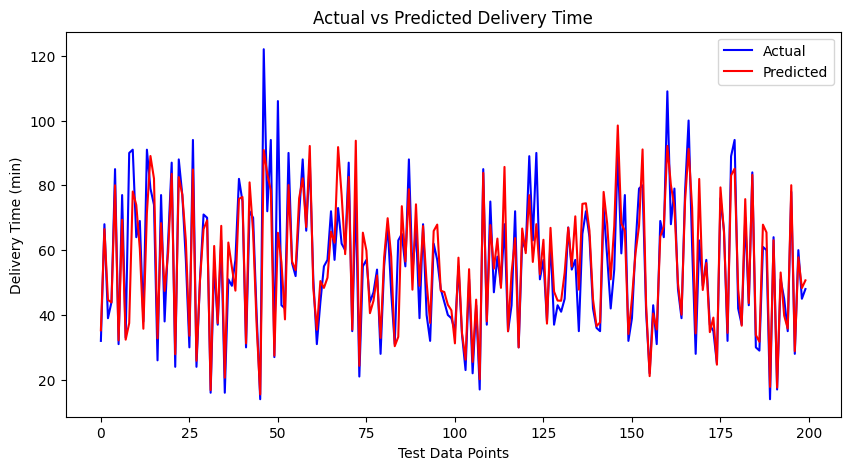

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(y_test.values, color='blue', label='Actual')
plt.plot(y_test_pred, color='red', label='Predicted')

plt.xlabel('Test Data Points')
plt.ylabel('Delivery Time (min)')
plt.title('Actual vs Predicted Delivery Time')
plt.legend()
plt.show()